# 🗞️ Tarea 1 – Parte 1: Recolección y limpieza de noticias

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

## Configuración inicial

| Parámetro | Valor |
| :--- | :--- |
| **Fecha de descarga** | 14 de octubre de 2026 (se registra también en `FECHA_DESCARGA` al ejecutar) |
| **Opción elegida** | **A – La República** (`larepublica.pe`) |
| **Categorías finales** | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| **URL base** | `https://larepublica.pe` |
| **RSS oficiales** | `https://larepublica.pe/rss/{politica, economia, deportes, ciencia, home}.xml` |
| **News sitemaps** | `https://larepublica.pe/sitemap/{politica, economia, deportes, ciencia}.xml` |
| **Portadas de sección** | `https://larepublica.pe/{politica, economia, deportes, ciencia, tecnologia}` |

### Estrategia de extracción (y por qué)

1. **`robots.txt` primero.** El archivo permite explícitamente `/rss/*` y `/sitemap/*`, y prohíbe
   la paginación de secciones (`/*/pag/*`, `/*/*/page/*`), el buscador y `/archivo/*`.
   Cada URL se valida contra esas reglas antes de pedirla (función `permitido`).
2. **Semillas:** RSS + news sitemaps + portadas de sección. Solo cubren las últimas ~48 horas
   (10–30 noticias por sección), insuficiente para 350+ noticias.
3. **Rastreo por enlaces relacionados:** como la paginación está prohibida, se aprovecha que cada
   artículo enlaza a ~10 notas de su misma sección (muchas de meses anteriores). Se recorre ese grafo
   en *round-robin* por categoría hasta llegar a la meta por categoría.
4. **Lectura del artículo:** el HTML canónico se sirve completo (comprimido con gzip; `requests` lo
   descomprime solo). Del HTML se extrae el titular (`<h1>`), la bajada (`og:description`), la fecha
   (`datePublished` del JSON-LD) y la sección web (`articleSection`).
5. **Buenas prácticas:** `User-Agent` descriptivo, pausa aleatoria de 1–2 s después de cada solicitud,
   máximo 1 reintento, y respaldo crudo en `datos/raw/`.


In [1]:
import json
import random
import re
import time
from collections import Counter, deque
from datetime import datetime
from pathlib import Path
from urllib.parse import urljoin, urlparse

import feedparser
import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup
from IPython.display import display

# Plotly interactivo + imagen estática (para que los gráficos se vean en GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.defaults.default_width, pio.defaults.default_height = 1000, 520
pd.set_option("display.max_colwidth", 120)

BASE = "https://larepublica.pe"
MEDIO = "La Republica"
FECHA_DESCARGA = datetime.now().strftime("%Y-%m-%d")
HEADERS = {
    "User-Agent": ("QLab-Tarea1/1.0 (proyecto academico de clasificacion de titulares; "
                   "scraping respetuoso; github.com/LuisGuevaraVega)"),
    "Accept-Language": "es-PE,es;q=0.9",
}
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
META_POR_CATEGORIA = 115      # algo más de 90-100 para absorber descartes en la limpieza
MAX_PETICIONES = 900          # tope de seguridad del rastreo
RE_SCRAPE = False             # True fuerza un scraping nuevo aunque exista el respaldo crudo

RAW = Path("datos/raw")
RAW.mkdir(parents=True, exist_ok=True)
RUTA_CRUDO = RAW / "articulos_crudos.csv"
RUTA_LOG = RAW / "log_peticiones.csv"

random.seed(42)
session = requests.Session()
session.headers.update(HEADERS)
print("Fecha de descarga:", FECHA_DESCARGA)

Fecha de descarga: 2026-10-14


## 1. `robots.txt` y cliente HTTP respetuoso

Se implementa un intérprete mínimo de `robots.txt` que soporta comodines `*` y `$` (el
`urllib.robotparser` estándar no los entiende, y La República los usa en reglas como
`/*/pag/*`). Ante dos reglas que coinciden, gana la más específica (la más larga), como hace Google.

In [2]:
def cargar_reglas_robots(url_robots):
    texto = session.get(url_robots, timeout=20).text
    (RAW / "robots.txt").write_text(texto, encoding="utf-8")
    reglas, agentes, en_reglas = [], [], False
    for linea in texto.splitlines():
        linea = linea.split("#")[0].strip()
        if ":" not in linea:
            continue
        clave, _, valor = linea.partition(":")
        clave, valor = clave.strip().lower(), valor.strip()
        if clave == "user-agent":
            if en_reglas:                       # empieza un grupo nuevo
                agentes, en_reglas = [], False
            agentes.append(valor.lower())
        elif clave in ("allow", "disallow"):
            en_reglas = True
            if "*" in agentes and valor:
                patron = re.escape(valor).replace(r"\*", ".*")
                if patron.endswith(r"\$"):
                    patron = patron[:-2] + "$"
                reglas.append((clave == "allow", len(valor), re.compile(patron)))
    return reglas


def permitido(url):
    ruta = urlparse(url).path or "/"
    coincidencias = [(largo, allow) for allow, largo, rx in REGLAS if rx.match(ruta)]
    if not coincidencias:
        return True
    largo_max = max(largo for largo, _ in coincidencias)
    return any(allow for largo, allow in coincidencias if largo == largo_max)


REGLAS = cargar_reglas_robots(f"{BASE}/robots.txt")
print(f"Reglas aplicables a User-agent *: {len(REGLAS)}")
for prueba in ["/rss/politica.xml", "/sitemap/ciencia.xml", "/politica/pag/2",
               "/deportes/2026/10/13/ejemplo-123", "/archivo/2026"]:
    print(f"  {prueba:<35} -> {'permitido' if permitido(BASE + prueba) else 'PROHIBIDO'}")

Reglas aplicables a User-agent *: 27
  /rss/politica.xml                   -> permitido
  /sitemap/ciencia.xml                -> permitido
  /politica/pag/2                     -> PROHIBIDO
  /deportes/2026/10/13/ejemplo-123    -> permitido
  /archivo/2026                       -> PROHIBIDO


In [3]:
LOG = []


def obtener(url, intentos=2):
    """GET con validación de robots.txt, pausa de 1-2 s y como máximo 1 reintento."""
    if not permitido(url):
        LOG.append({"url": url, "estado": "bloqueado_robots", "hora": datetime.now().isoformat()})
        return None
    for intento in range(intentos):
        try:
            r = session.get(url, timeout=25)
            estado = r.status_code
        except requests.RequestException as e:
            r, estado = None, f"error:{type(e).__name__}"
        LOG.append({"url": url, "estado": estado, "intento": intento + 1,
                    "hora": datetime.now().isoformat()})
        time.sleep(random.uniform(1, 2))
        if r is not None and r.status_code == 200:
            return r.text
        if r is not None and r.status_code in (404, 410):
            return None
    return None

## 2. Funciones de extracción

* `normalizar`: deja las URLs en forma canónica (sin parámetros, sin `/amp/`, con dominio).
* `PATRON_ARTICULO`: reconoce URLs de artículo (`/seccion[/subseccion]/AAAA/MM/DD/slug`).
* La **sección original** se toma de la ruta de la URL (p. ej. `economia/precio-del-dolar`), que es
  como el diario clasifica la nota en su web.

In [4]:
PATRON_ARTICULO = re.compile(
    r"^https://larepublica\.pe/(?P<seccion>[a-z0-9-]+(?:/[a-z0-9-]+)*)/"
    r"(?P<anio>20\d{2})/(?P<mes>\d{2})/(?P<dia>\d{2})/(?P<slug>[a-z0-9-]+)$"
)
# primer segmento de la ruta -> categoría a la que se dirige el rastreo
SECCION_A_CATEGORIA_RASTREO = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}


def normalizar(url):
    url = urljoin(BASE, url.strip()).split("#")[0].split("?")[0].rstrip("/")
    return url.replace("https://larepublica.pe/amp/", "https://larepublica.pe/")


def seccion_de_url(url):
    m = PATRON_ARTICULO.match(url)
    return m["seccion"] if m else None


def categoria_rastreo(url):
    seccion = seccion_de_url(url)
    return SECCION_A_CATEGORIA_RASTREO.get(seccion.split("/")[0]) if seccion else None


def enlaces_de_articulos(html):
    soup = BeautifulSoup(html, "lxml")
    urls = {normalizar(a["href"]) for a in soup.find_all("a", href=True)}
    return {u for u in urls if PATRON_ARTICULO.match(u)}


def parsear_articulo(html, url):
    soup = BeautifulSoup(html, "lxml")

    def meta(clave):
        tag = soup.find("meta", property=clave) or soup.find("meta", attrs={"name": clave})
        return tag["content"].strip() if tag and tag.get("content") else None

    h1 = soup.find("h1")
    titular = h1.get_text(" ", strip=True) if h1 else meta("og:title")
    fecha, seccion_web = None, None
    for script in soup.find_all("script", type="application/ld+json"):
        try:
            datos = json.loads(script.string or "")
        except json.JSONDecodeError:
            continue
        nodos = datos if isinstance(datos, list) else datos.get("@graph", [datos])
        for nodo in nodos:
            if isinstance(nodo, dict) and "NewsArticle" in str(nodo.get("@type", "")):
                fecha = fecha or nodo.get("datePublished")
                seccion_web = seccion_web or nodo.get("articleSection")
    return {
        "titular": titular,
        "bajada": meta("og:description") or meta("description"),
        "medio": MEDIO,
        "seccion_original": seccion_de_url(url),
        "seccion_web": seccion_web,
        "url": url,
        "fecha": fecha[:10] if fecha else None,
    }

## 3. Semillas: RSS, news sitemaps y portadas de sección

El RSS `home.xml` mezcla todas las secciones del diario (mundo, sociedad, espectáculos…). Esas
noticias se guardan tal cual en el respaldo crudo para **documentar en la limpieza las que no encajan
en las 4 categorías** (no se inventa una quinta).

In [5]:
def semillas():
    urls, registros_rss = set(), []
    for nombre in ["politica", "economia", "deportes", "ciencia", "home"]:
        xml = obtener(f"{BASE}/rss/{nombre}.xml")
        if not xml:
            print(f"  RSS {nombre}: sin respuesta")
            continue
        (RAW / f"rss_{nombre}.xml").write_text(xml, encoding="utf-8")
        feed = feedparser.parse(xml)
        for item in feed.entries:
            url = normalizar(item.link)
            urls.add(url)
            if nombre == "home":   # se conserva tal cual para el reporte de descartes
                fecha = item.get("published_parsed")
                registros_rss.append({
                    "titular": item.title.strip(),
                    "bajada": BeautifulSoup(item.get("summary", ""), "lxml").get_text(" ", strip=True),
                    "medio": MEDIO, "seccion_original": seccion_de_url(url),
                    "seccion_web": item.tags[0].term if item.get("tags") else None,
                    "url": url,
                    "fecha": time.strftime("%Y-%m-%d", fecha) if fecha else None,
                    "fuente": "rss_home",
                })
        print(f"  RSS {nombre:<9}: {len(feed.entries):>3} items")
    for nombre in ["politica", "economia", "deportes", "ciencia"]:
        xml = obtener(f"{BASE}/sitemap/{nombre}.xml")
        if xml:
            (RAW / f"sitemap_{nombre}.xml").write_text(xml, encoding="utf-8")
            locs = re.findall(r"<loc>\s*([^<\s]+)\s*</loc>", xml)
            urls.update(normalizar(u) for u in locs)
            print(f"  sitemap {nombre:<9}: {len(locs):>3} URLs")
    for nombre in ["politica", "economia", "deportes", "ciencia", "tecnologia"]:
        html = obtener(f"{BASE}/{nombre}")
        if html:
            (RAW / f"portada_{nombre}.html").write_text(html, encoding="utf-8")
            encontrados = enlaces_de_articulos(html)
            urls.update(encontrados)
            print(f"  portada {nombre:<10}: {len(encontrados):>3} enlaces a artículos")
    return {u for u in urls if PATRON_ARTICULO.match(u)}, registros_rss

## 4. Rastreo por enlaces relacionados (round-robin por categoría)

Cada categoría tiene su propia cola. En cada vuelta se toma una URL de cada categoría que aún no
llegó a la meta, se descarga el artículo, se guardan sus datos y se encolan los enlaces a otras notas
de las secciones objetivo. Así el corpus queda balanceado sin depender de la paginación prohibida.

> Si ya existe el respaldo crudo (`datos/raw/articulos_crudos.csv`) y `RE_SCRAPE = False`, se carga
> el respaldo en lugar de volver a descargar todo (para no sobrecargar al medio en cada ejecución).

In [6]:
def rastrear(urls_semilla):
    colas = {c: deque() for c in CATEGORIAS}
    vistos, registros, conteo = set(), [], Counter()

    def encolar(url):
        cat = categoria_rastreo(url)
        if cat and url not in vistos:
            vistos.add(url)
            colas[cat].append(url)

    for u in sorted(urls_semilla):
        encolar(u)
    print("Cola inicial:", {c: len(q) for c, q in colas.items()})

    peticiones, inicio = 0, time.time()
    while peticiones < MAX_PETICIONES:
        pendientes = [c for c in CATEGORIAS if conteo[c] < META_POR_CATEGORIA and colas[c]]
        if not pendientes:
            break
        for cat in pendientes:
            url = colas[cat].popleft()
            html = obtener(url)
            peticiones += 1
            if not html:
                continue
            registro = parsear_articulo(html, url)
            registro["fuente"] = "rastreo_html"
            registros.append(registro)
            conteo[cat] += 1
            for enlace in enlaces_de_articulos(html):
                encolar(enlace)
        if peticiones % 40 < len(pendientes):
            print(f"  {peticiones:>4} peticiones | {dict(conteo)} | {time.time() - inicio:.0f} s")
    print(f"Fin del rastreo: {peticiones} peticiones en {time.time() - inicio:.0f} s")
    return registros


if RUTA_CRUDO.exists() and not RE_SCRAPE:
    crudo = pd.read_csv(RUTA_CRUDO)
    log = pd.read_csv(RUTA_LOG)
    horas = pd.to_datetime(log["hora"])
    print(f"Respaldo crudo cargado: {len(crudo)} registros.")
    print(f"Scraping original: {horas.min():%Y-%m-%d %H:%M} – {horas.max():%H:%M} "
          f"({(horas.max() - horas.min()).total_seconds() / 60:.0f} min, {len(log)} peticiones, "
          f"pausa media entre peticiones = {horas.diff().dt.total_seconds().median():.1f} s)")
    html = crudo[crudo["fuente"] == "rastreo_html"]
    print("Artículos leídos del HTML por categoría de rastreo:",
          dict(Counter(html["url"].map(categoria_rastreo))))
else:
    urls_semilla, registros_rss = semillas()
    print(f"URLs semilla de artículos: {len(urls_semilla)}")
    registros_html = rastrear(urls_semilla)
    crudo = pd.DataFrame(registros_html + registros_rss)
    crudo.to_csv(RUTA_CRUDO, index=False)
    log = pd.DataFrame(LOG)
    log.to_csv(RUTA_LOG, index=False)
    print(f"Respaldo crudo guardado en {RUTA_CRUDO}: {len(crudo)} registros")

print("\nEstados HTTP del log de peticiones:")
display(log["estado"].astype(str).value_counts().to_frame("peticiones"))
print("Registros crudos por fuente:")
display(crudo["fuente"].value_counts().to_frame("n"))

Respaldo crudo cargado: 660 registros.
Scraping original: 2026-10-14 11:55 – 12:09 (14 min, 474 peticiones, pausa media entre peticiones = 1.8 s)
Artículos leídos del HTML por categoría de rastreo: {'politica': 115, 'economia': 115, 'deportes': 115, 'ciencia_tecnologia': 115}

Estados HTTP del log de peticiones:


,peticiones
estado,
200,474


Registros crudos por fuente:


,n
fuente,
rastreo_html,460
rss_home,200


## 5. Limpieza y normalización

Pasos, en este orden, registrando cuántas filas elimina cada uno:

1. URLs duplicadas (una nota puede llegar por RSS y por rastreo; se conserva la versión leída del HTML).
2. Titulares vacíos.
3. Titulares duplicados con distinta URL (el diario a veces republica la misma nota).
4. Noticias de secciones que **no encajan** en las 4 categorías (mundo, sociedad, espectáculos, etc.).

In [7]:
df = crudo.copy()
df["titular"] = df["titular"].fillna("").str.strip().str.replace(r"\s+", " ", regex=True)
df["bajada"] = df["bajada"].fillna("").str.strip().str.replace(r"\s+", " ", regex=True)
descartes = []

def registrar(motivo, filas):
    descartes.append({"motivo": motivo, "n": len(filas),
                      "ejemplo": filas["titular"].iloc[0][:90] if len(filas) else ""})

# 1) URL duplicada (se prioriza el registro del HTML sobre el del RSS)
df["prioridad"] = (df["fuente"] != "rastreo_html").astype(int)
df = df.sort_values("prioridad")
registrar("URL duplicada", df[df.duplicated("url")])
df = df.drop_duplicates("url")

# 2) titular vacío
registrar("Titular vacío", df[df["titular"] == ""])
df = df[df["titular"] != ""]

# 3) mismo titular con otra URL
registrar("Titular duplicado (otra URL)", df[df.duplicated("titular")])
df = df.drop_duplicates("titular")
print(f"Filas tras quitar duplicados y vacíos: {len(df)} (de {len(crudo)} crudas)")

Filas tras quitar duplicados y vacíos: 598 (de 660 crudas)


### Tabla de equivalencias `seccion_original` → categoría final

El mapeo se hace sobre el **primer segmento** de la ruta. Las subsecciones (p. ej.
`economia/precio-del-dolar`, `deportes/futbol-peruano`) heredan la categoría de su sección madre,
y `ciencia` y `tecnologia` se unifican en `ciencia_tecnologia`. Cualquier otra sección se descarta.

In [8]:
MAPEO_SECCION = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}

df["seccion_madre"] = df["seccion_original"].fillna("(sin seccion)").str.split("/").str[0]
df["etiqueta"] = df["seccion_madre"].map(MAPEO_SECCION)

tabla_mapeo = (df.groupby(["seccion_original", "etiqueta"], dropna=False)
                 .size().rename("noticias").reset_index()
                 .sort_values(["etiqueta", "noticias"], ascending=[True, False]))
tabla_mapeo["etiqueta"] = tabla_mapeo["etiqueta"].fillna("— descartada —")
display(tabla_mapeo.reset_index(drop=True))

# 4) secciones fuera de las 4 categorías
fuera = df[df["etiqueta"].isna()]
registrar("Sección fuera de las 4 categorías", fuera)
if len(fuera):
    print("Secciones descartadas:", dict(Counter(fuera["seccion_madre"])))
df = df[df["etiqueta"].notna()].copy()

,seccion_original,etiqueta,noticias
0,ciencia,ciencia_tecnologia,84
1,tecnologia,ciencia_tecnologia,23
2,tecnologia/smartphone,ciencia_tecnologia,4
3,tecnologia/tutoriales,ciencia_tecnologia,2
4,tecnologia/actualidad,ciencia_tecnologia,1
5,deportes,deportes,111
6,deportes/alianza-lima,deportes,1
7,deportes/beisbol,deportes,1
8,deportes/mundial-qatar-2022,deportes,1
9,economia,economia,102


Secciones descartadas: {'latinos-en-usa': 11, 'entretenimiento': 7, 'mundo': 14, 'sociedad': 45, 'opinion': 13, 'espectaculos': 26, 'cultural': 4, 'mastergrama': 2, 'carlincatura': 2, 'horoscopo': 2, 'cine-series': 4, 'verificador': 4, 'publirreportajes': 1, 'nota-de-prensa': 1, '(sin seccion)': 1, 'servicios': 2, 'cultura-asiatica': 1}


In [9]:
reporte = pd.DataFrame(descartes)
print(f"Registros crudos: {len(crudo)} | descartados: {reporte['n'].sum()} | finales: {len(df)}")
display(reporte)
print("Bajadas vacías en el dataset final:", int((df["bajada"] == "").sum()))
print("Noticias por categoría:")
display(df["etiqueta"].value_counts().to_frame("n"))

Registros crudos: 660 | descartados: 202 | finales: 458


,motivo,n,ejemplo
0,URL duplicada,60,Previa Manchester City vs PSG EN VIVO: a qué hora y dónde ver el partido de hoy por la Cha
1,Titular vacío,0,
2,Titular duplicado (otra URL),2,Google Discover: cómo seguir a La República desde tu celular y recibir sus noticias al ins
3,Sección fuera de las 4 categorías,140,Alerta máxima para clientes en Walmart | Decenas de personas sufrieron una posible intoxic


Bajadas vacías en el dataset final: 0
Noticias por categoría:


,n
etiqueta,
politica,115
economia,115
deportes,114
ciencia_tecnologia,114


## 6. Análisis exploratorio (EDA)

Cada gráfico lleva como título la **conclusión analítica** que se lee en él (redactada después de
revisar los datos), no solo el nombre de la variable.

In [10]:
_fechas = pd.to_datetime(df["fecha"], errors="coerce")
_largo = df["titular"].str.len()
_n_cat = df["etiqueta"].value_counts()
_recientes = (_fechas >= "2026-09-01").mean()
_mediana = _largo.groupby(df["etiqueta"]).median()

TITULO_FIG1 = (f"Corpus balanceado: entre {_n_cat.min()} y {_n_cat.max()} noticias por categoría"
               f"<br><sup>Ninguna clase domina, el modelo no puede ganar prediciendo la mayoritaria</sup>")
TITULO_FIG2 = (f"El {_recientes:.0%} de las noticias es de septiembre–octubre de 2026"
               f"<br><sup>El rastreo por enlaces favorece lo reciente; hay una cola de notas desde 2020</sup>")
TITULO_FIG3 = (f"Ciencia y tecnología titula más largo que política "
               f"(mediana {_mediana['ciencia_tecnologia']:.0f} vs {_mediana['politica']:.0f} caracteres)"
               f"<br><sup>Las distribuciones se solapan: la longitud sola no basta para clasificar</sup>")

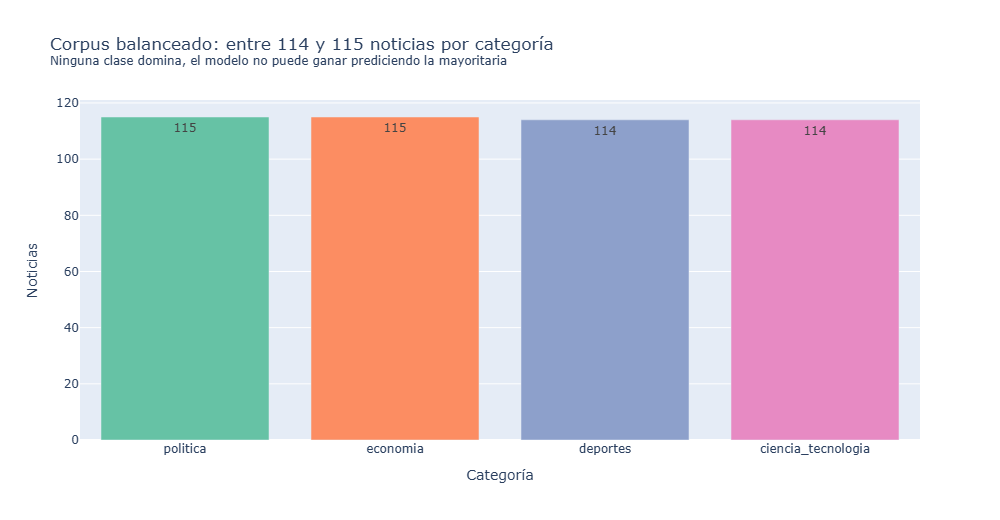

In [11]:
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
df["largo_titular"] = df["titular"].str.len()

conteo_cat = df["etiqueta"].value_counts().reindex(CATEGORIAS)
fig1 = px.bar(
    x=conteo_cat.index, y=conteo_cat.values, text=conteo_cat.values,
    labels={"x": "Categoría", "y": "Noticias"},
    color=conteo_cat.index, color_discrete_sequence=px.colors.qualitative.Set2,
    title=TITULO_FIG1,
)
fig1.update_layout(showlegend=False)
fig1.show()

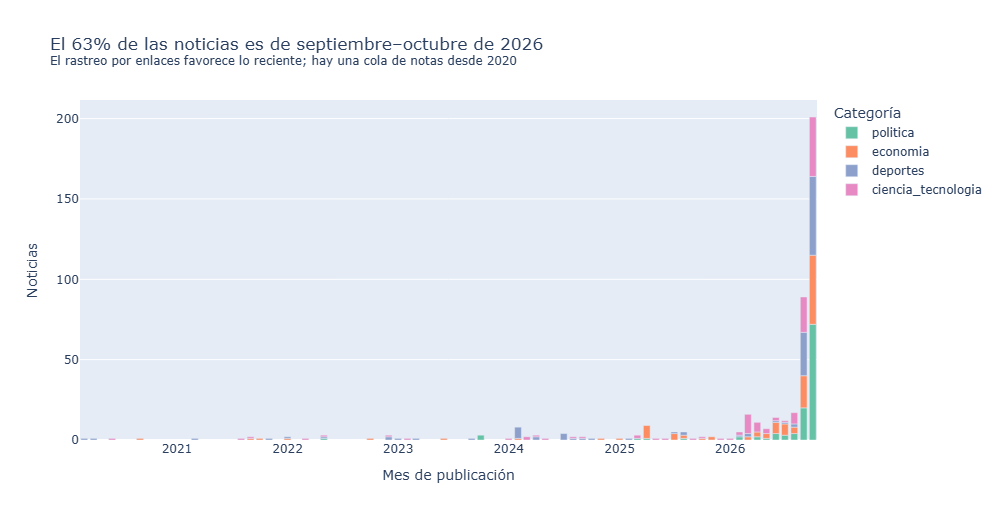

Rango de fechas: 2020-03-15 a 2026-10-14


fecha,2020-03,2020-04,2020-06,2020-09,2021-03,2021-08,2021-09,2021-10,2021-11,2022-01,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
noticias,1,1,1,1,1,1,2,1,1,2,...,1,5,16,11,7,14,12,17,89,201


In [12]:
df["mes"] = df["fecha"].dt.to_period("M").dt.to_timestamp()
por_mes = df.groupby(["mes", "etiqueta"]).size().rename("noticias").reset_index()
fig2 = px.bar(
    por_mes, x="mes", y="noticias", color="etiqueta",
    category_orders={"etiqueta": CATEGORIAS},
    color_discrete_sequence=px.colors.qualitative.Set2,
    labels={"mes": "Mes de publicación", "noticias": "Noticias", "etiqueta": "Categoría"},
    title=TITULO_FIG2,
)
fig2.show()
print(f"Rango de fechas: {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")
display(df.groupby(df["fecha"].dt.to_period("M")).size().rename("noticias").to_frame().T)

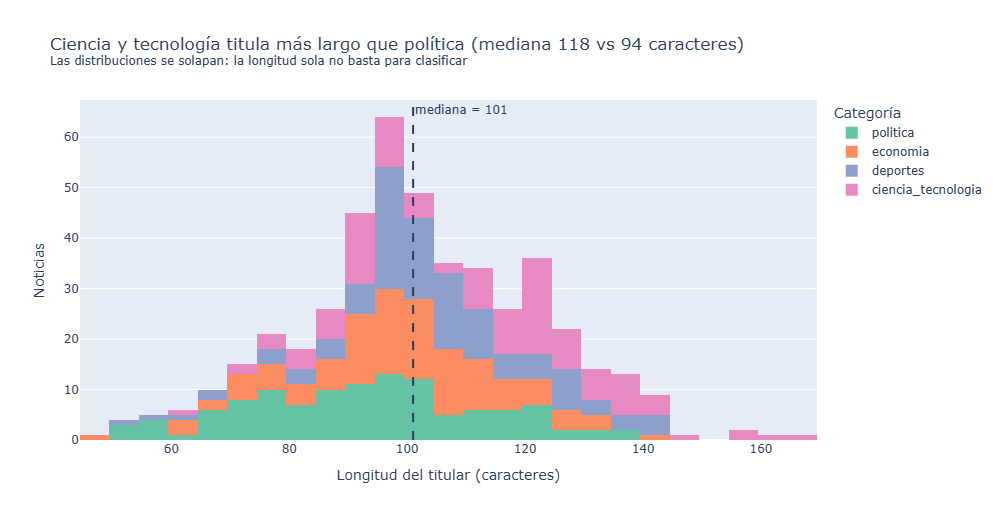

,count,mean,std,min,25%,50%,75%,max
etiqueta,,,,,,,,
ciencia_tecnologia,114.0,112.3,21.4,62.0,94.0,117.5,125.8,168.0
deportes,114.0,105.0,17.8,52.0,97.0,103.0,113.8,143.0
economia,115.0,99.4,16.9,49.0,90.5,100.0,110.0,142.0
politica,115.0,92.9,20.0,50.0,78.5,94.0,105.5,138.0


In [13]:
fig3 = px.histogram(
    df, x="largo_titular", nbins=30, color="etiqueta",
    category_orders={"etiqueta": CATEGORIAS},
    color_discrete_sequence=px.colors.qualitative.Set2, barmode="stack",
    labels={"largo_titular": "Longitud del titular (caracteres)", "count": "Noticias",
            "etiqueta": "Categoría"},
    title=TITULO_FIG3,
)
fig3.update_layout(yaxis_title="Noticias")
fig3.add_vline(x=df["largo_titular"].median(), line_dash="dash",
               annotation_text=f"mediana = {df['largo_titular'].median():.0f}")
fig3.show()
display(df.groupby("etiqueta")["largo_titular"].describe().round(1))

## 7. Validación: titulares más largos y más cortos

Se revisa que los extremos sean titulares reales (no menús, firmas o texto basura) y que sus
longitudes coincidan con las colas del histograma.

In [14]:
cols = ["largo_titular", "etiqueta", "titular"]
print("5 titulares MÁS LARGOS:")
display(df.nlargest(5, "largo_titular")[cols])
print("5 titulares MÁS CORTOS:")
display(df.nsmallest(5, "largo_titular")[cols])
print(f"Mínimo: {df['largo_titular'].min()} | máximo: {df['largo_titular'].max()} "
      f"(coinciden con los extremos del histograma)")

5 titulares MÁS LARGOS:


,largo_titular,etiqueta,titular
119,168,ciencia_tecnologia,"En 1970, la NASA puso en órbita 2 ranas toro para monitorear el mareo espacial: durante 6 días registraron 139 horas..."
215,163,ciencia_tecnologia,Lo encontraron 2.000 años después con un tazón para protegerse la cabeza y una lámpara para iluminar su camino: un h...
355,159,ciencia_tecnologia,Una expedición explora el fondo del Atlántico y encuentra un problema que preocupa a científicos: más de 200.000 rec...
363,158,ciencia_tecnologia,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sug..."
19,148,ciencia_tecnologia,"Australia recuperó sus praderas marinas tras un ciclón y grandes inundaciones, pero los científicos descubrieron que..."


5 titulares MÁS CORTOS:


,largo_titular,etiqueta,titular
305,49,economia,Es hora de que el Perú produzca sus fertilizantes
156,50,politica,Fugó cabecilla de la banda que mató a “China Polo”
432,51,politica,Solo hay un médico por cada 550 pacientes de la PNP
234,52,deportes,Falleció exzaguero del FBC Melgar Jorge ‘Tata’ Reyes
12,54,politica,Minería ilegal elevó 8 veces la demanda de combustible


Mínimo: 49 | máximo: 168 (coinciden con los extremos del histograma)


### Lectura del EDA

* **Balance:** el rastreo *round-robin* dejó las 4 categorías prácticamente iguales, así que el
  clasificador no aprenderá a favorecer una clase por frecuencia.
* **Sesgo temporal:** la mayoría de noticias son de septiembre–octubre de 2026 (las semillas del RSS
  son de las últimas 48 h y los enlaces relacionados apuntan sobre todo a notas recientes); hay una cola
  de notas antiguas (desde 2020) enlazadas como contexto. El modelo verá sobre todo la agenda reciente.
* **Estilo:** ciencia y tecnología usa titulares largos y narrativos (*"Lo encontraron 2.000 años
  después…"*), mientras política y economía son más cortos y directos. La longitud por sí sola ya
  aporta algo de señal, pero se solapa bastante entre categorías.
* **Validación:** los extremos (49 y 168 caracteres) son titulares reales y completos, y coinciden con
  las colas del histograma: no hay menús, firmas ni texto basura colado.

## 8. Exportación de `datos/noticias.csv`

In [15]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df.sort_values(["etiqueta", "fecha"], ascending=[True, False])[COLUMNAS].copy()
final["fecha"] = final["fecha"].dt.strftime("%Y-%m-%d")
final = final.reset_index(drop=True)
final.to_csv("datos/noticias.csv", index=False, encoding="utf-8")

print("df.shape:", final.shape)
display(final.head(5))

df.shape: (458, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Los ingenieros de la Unión Soviética perforaron 12 kilómetros en la corteza terrestre y se toparon con algo que no e...,El calor era tan intenso que deformó las herramientas de excavación y se convirtió en un reto para continuar con el ...,La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/12/los-ingenieros-de-la-union-sovietica-perforaron-12-kilometros-en-la-cortez...,2026-10-13,ciencia_tecnologia
1,Científicos de la Universidad de Stanford encuentran la forma de regenerar el cartílago de la rodilla y reducir el r...,"El estudio, publicado en Science, se centra en bloquear la proteína 15-PGDH, cuyo aumento en los tejidos se relacion...",La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/13/cientificos-de-la-universidad-de-stanford-encuentran-la-forma-de-regenerar...,2026-10-13,ciencia_tecnologia
2,Científicos crean nuevo tipo de “superhielo”: 10 veces más resistente que el hielo común y casi tan fuerte como el c...,El innovador material utiliza componentes de origen vegetal y una proteína especial para evitar que las grietas se e...,La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/11/cientificos-crean-nuevo-tipo-de-superhielo-10-veces-mas-resistente-que-el-...,2026-10-12,ciencia_tecnologia
3,Eliminaron 6.000 ratas y 60 cabras de una isla donde solo quedaba un árbol: sin plantar nada la vegetación aumentó u...,"Tras la eliminación de las especies invasoras de esta isla caribeña, la vegetación volvió a crecer por sí sola y num...",La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/11/eliminaron-6000-ratas-y-60-cabras-de-una-isla-donde-solo-quedaba-un-arbol-...,2026-10-12,ciencia_tecnologia
4,Frente a las costas de Alaska deriva desde 1931 un barco fantasma de 1322 toneladas que nadie logró traer de vuelta ...,"La historia de esta embarcación alimentó durante años las leyendas marítimas entre los navegantes, quienes aún lo ve...",La Republica,ciencia,https://larepublica.pe/ciencia/2026/10/11/frente-a-las-costas-de-alaska-deriva-desde-1931-un-barco-fantasma-de-1322-...,2026-10-12,ciencia_tecnologia
